In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [4]:
movies = pd.read_csv("CLEANED_DATA\movies.csv")
genres = pd.read_csv("CLEANED_DATA\genres.csv")
cast = pd.read_csv("CLEANED_DATA\cast.csv")
crew = pd.read_csv("CLEANED_DATA\crew.csv")
movie_keywords = pd.read_csv("CLEANED_DATA\movie_keywords.csv")
movie_genres = pd.read_csv("CLEANED_DATA\movie_genres.csv")

In [5]:
movies['release_date'] = pd.to_datetime(
    movies['release_date'],
    errors='coerce'
)

# UNIVARIATE

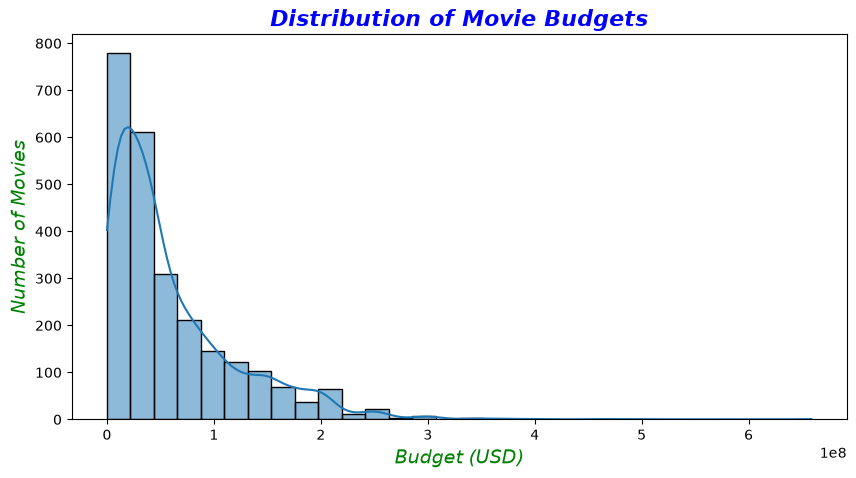

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    movies[movies['budget'] > 0]['budget'],
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Budgets",fontsize=16,fontweight='bold',color='b',fontstyle='italic')
plt.xlabel("Budget (USD)",fontsize=14,color='g',fontstyle='italic')
plt.ylabel("Number of Movies",fontsize=14,color='g',fontstyle='italic')

plt.show()

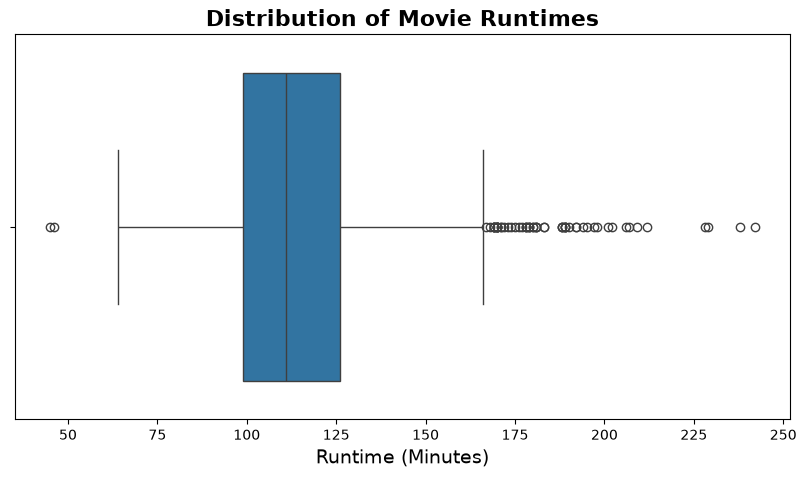

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=movies['runtime'].dropna()
)

plt.title("Distribution of Movie Runtimes",
          fontsize=16, fontweight='bold')

plt.xlabel("Runtime (Minutes)", fontsize=14)

plt.show()

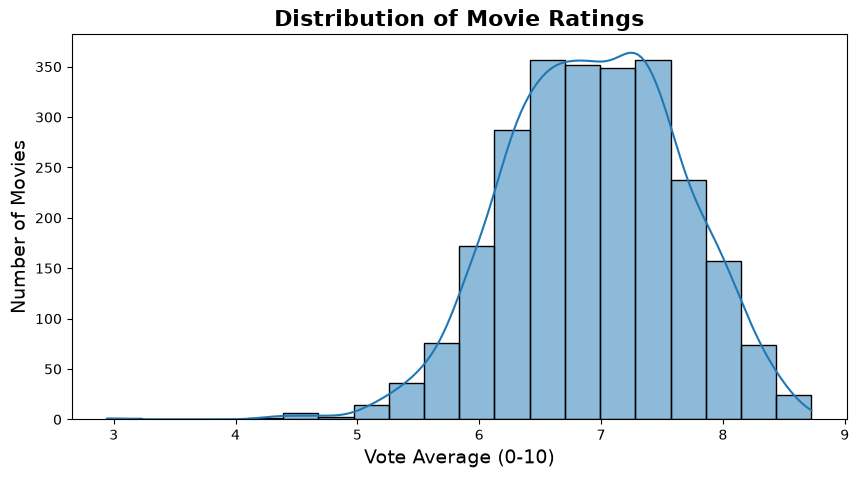

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    movies['vote_average'].dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Ratings",
          fontsize=16, fontweight='bold')

plt.xlabel("Vote Average (0-10)", fontsize=14)
plt.ylabel("Number of Movies", fontsize=14)

plt.show()

In [23]:
genre_data = movie_genres.merge(
    genres,
    on='genre_id',
    how='left'
)

genre_counts = genre_data.groupby('genre_name')['movie_id'].nunique()

print(genre_counts)

genre_name
Action             808
Adventure          674
Animation          246
Comedy             762
Crime              387
Documentary          1
Drama              937
Family             344
Fantasy            396
History            112
Horror             339
Music               49
Mystery            216
Romance            349
Science Fiction    463
TV Movie             4
Thriller           673
War                 85
Western             33
Name: movie_id, dtype: int64


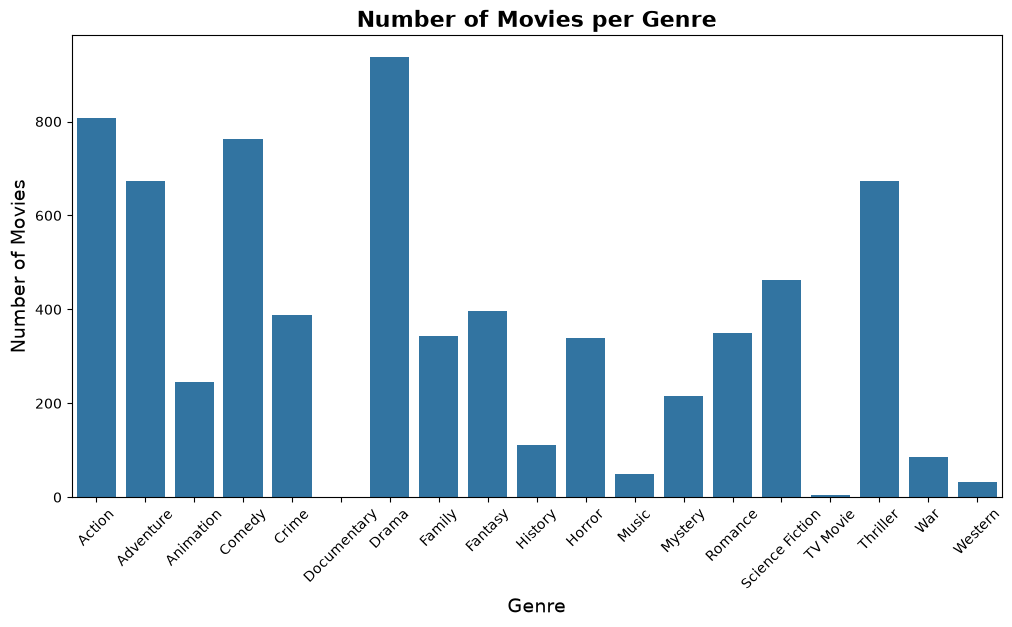

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values
)

plt.title("Number of Movies per Genre",
          fontsize=16, fontweight='bold')

plt.xlabel("Genre", fontsize=14)
plt.ylabel("Number of Movies", fontsize=14)

plt.xticks(rotation=45)

plt.show()

# BIVARIATE

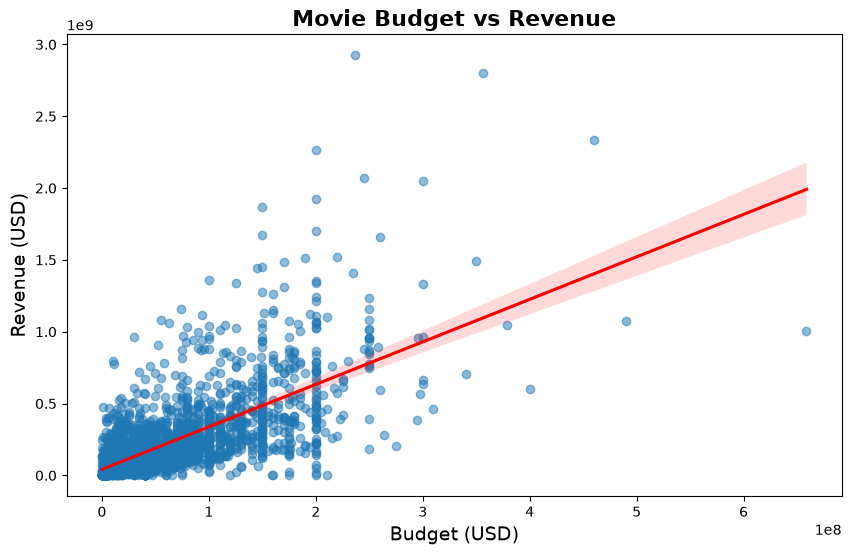

In [34]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=movies,
    x='budget',
    y='revenue',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title("Movie Budget vs Revenue",
          fontsize=16, fontweight='bold')

plt.xlabel("Budget (USD)", fontsize=14)
plt.ylabel("Revenue (USD)", fontsize=14)

plt.show()

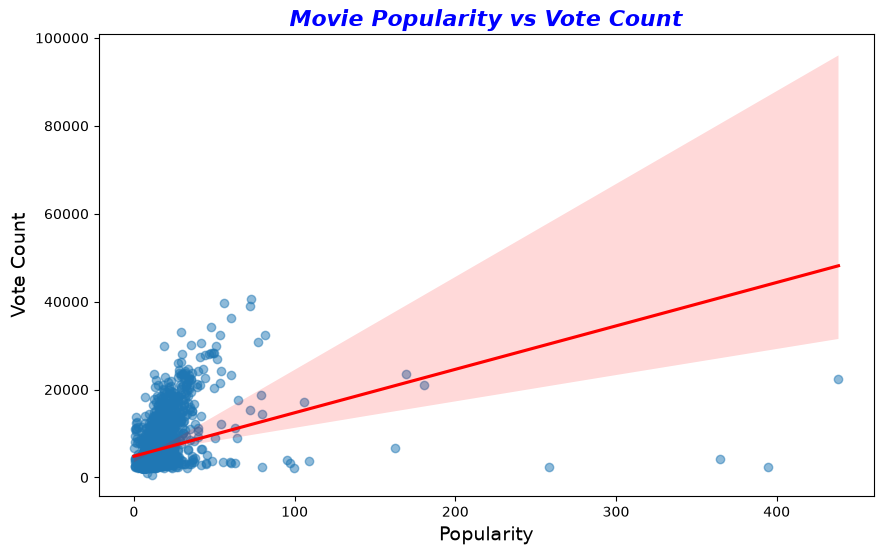

In [36]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=movies,
    x = 'popularity',
    y = 'vote_count',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)
plt.title("Movie Popularity vs Vote Count", fontsize=16, fontweight='bold',color='b',fontstyle='italic')
plt.xlabel("Popularity", fontsize=14)
plt.ylabel("Vote Count", fontsize=14)
plt.show()

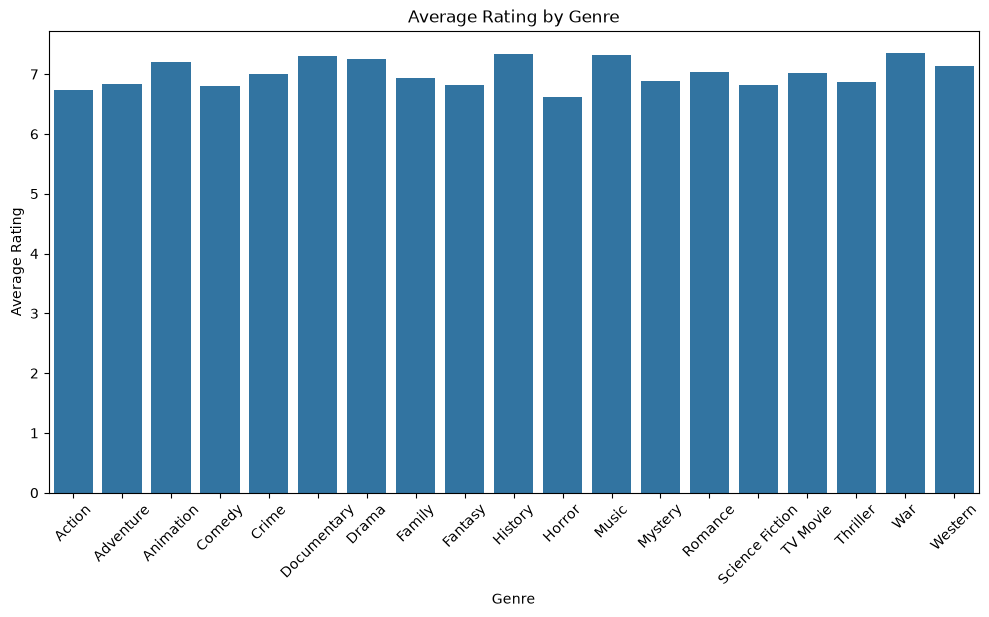

In [37]:
rating_data = movie_genres.merge(genres, on='genre_id').merge( movies[['movie_id', 'vote_average']], on='movie_id')
genre_ratings = rating_data.groupby('genre_name')['vote_average'].mean()
plt.figure(figsize=(12, 6))
sns.barplot(x=genre_ratings.index, y=genre_ratings.values)
plt.title("Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)

plt.show()

release_date
1921     1
1922     1
1927     1
1931     2
1936     1
        ..
2022    65
2023    62
2024    43
2025    26
2026     8
Name: count, Length: 89, dtype: int64
Highest movie output year: 2016
Number of movies: 121


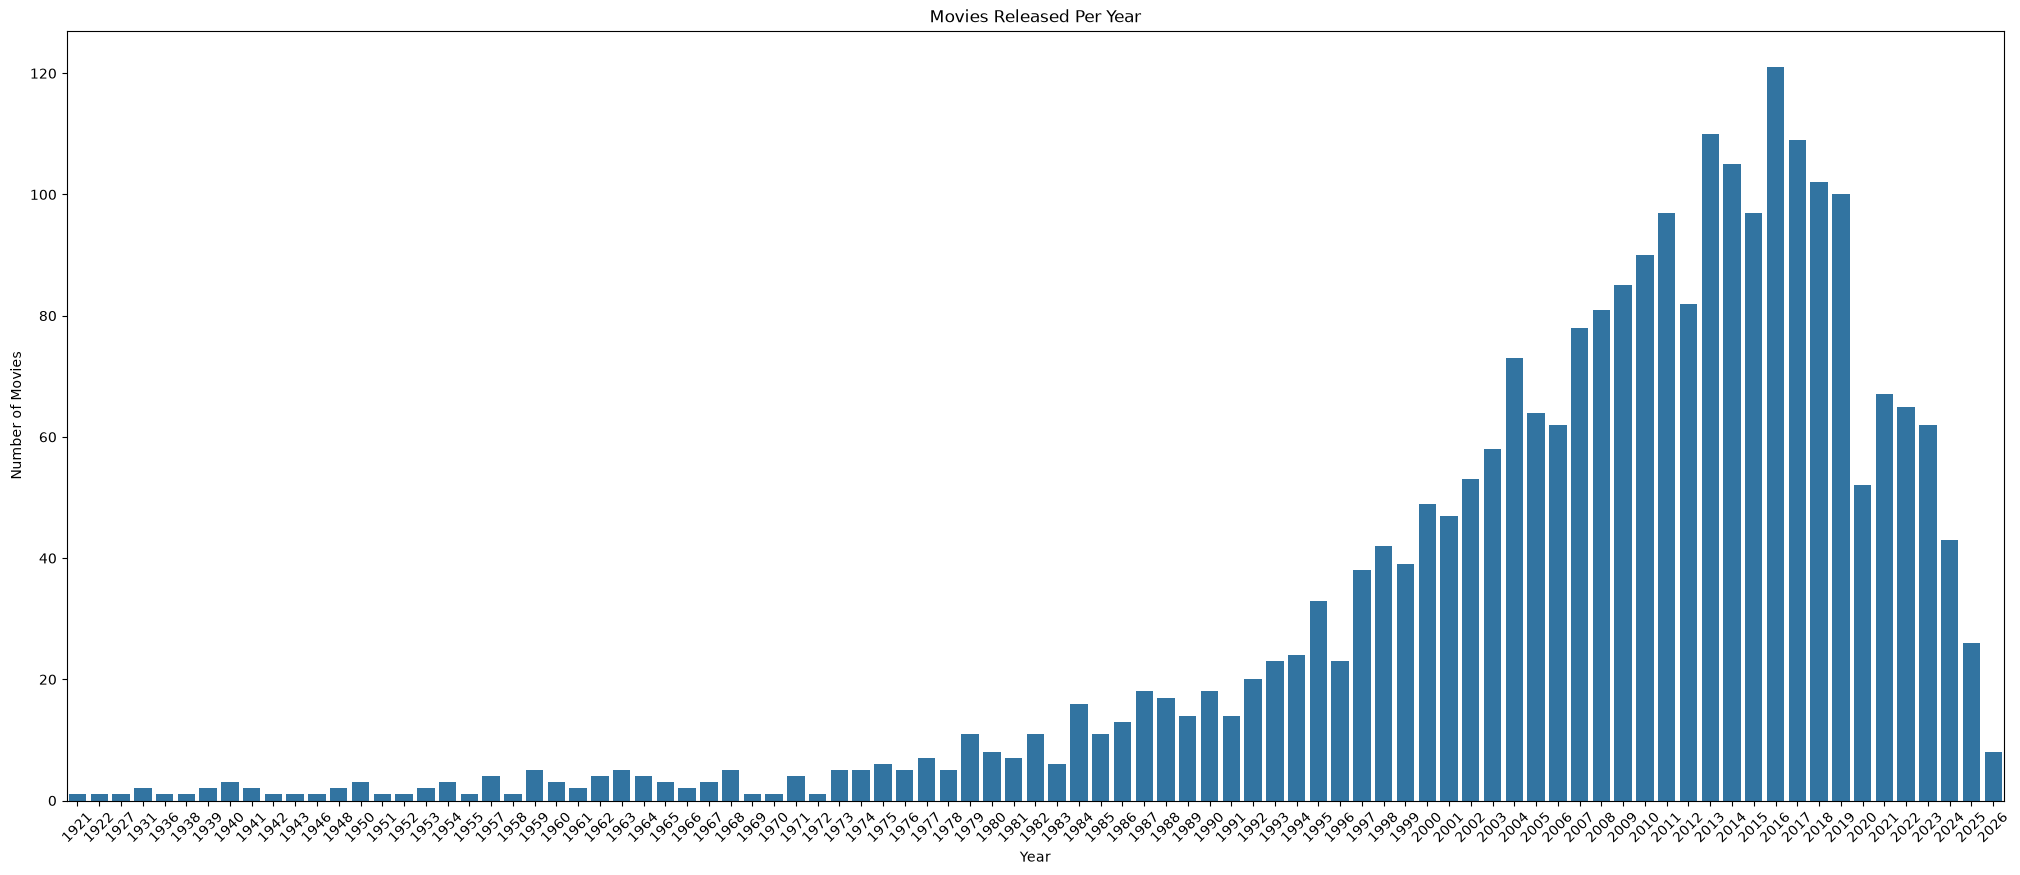

In [42]:
yearly_movies = pd.to_datetime(movies['release_date']).dt.year.value_counts().sort_index()

print(yearly_movies)

print("Highest movie output year:", yearly_movies.idxmax())
print("Number of movies:", yearly_movies.max())

plt.figure(figsize=(25, 10))

sns.barplot(x=yearly_movies.index, y=yearly_movies.values)

plt.title("Movies Released Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.show()

# MULTIVARIATE

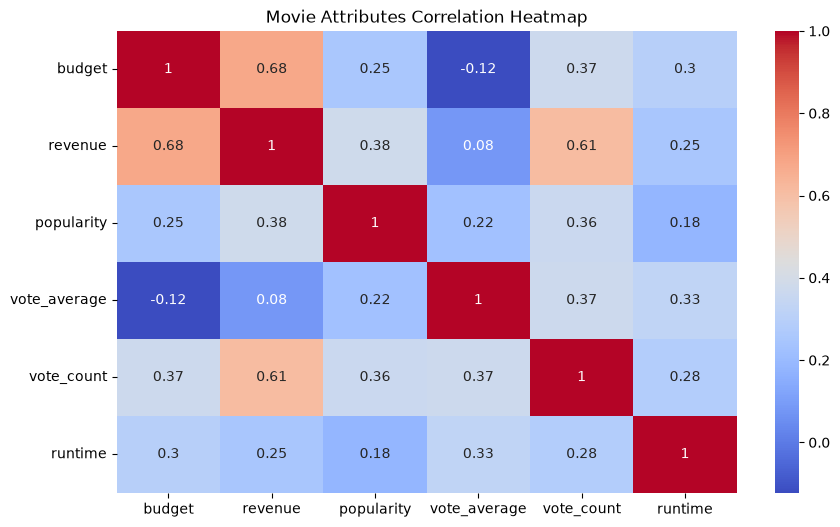

In [43]:
numeric_data = movies[['budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'runtime']]
corr = numeric_data.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Movie Attributes Correlation Heatmap")
plt.show()

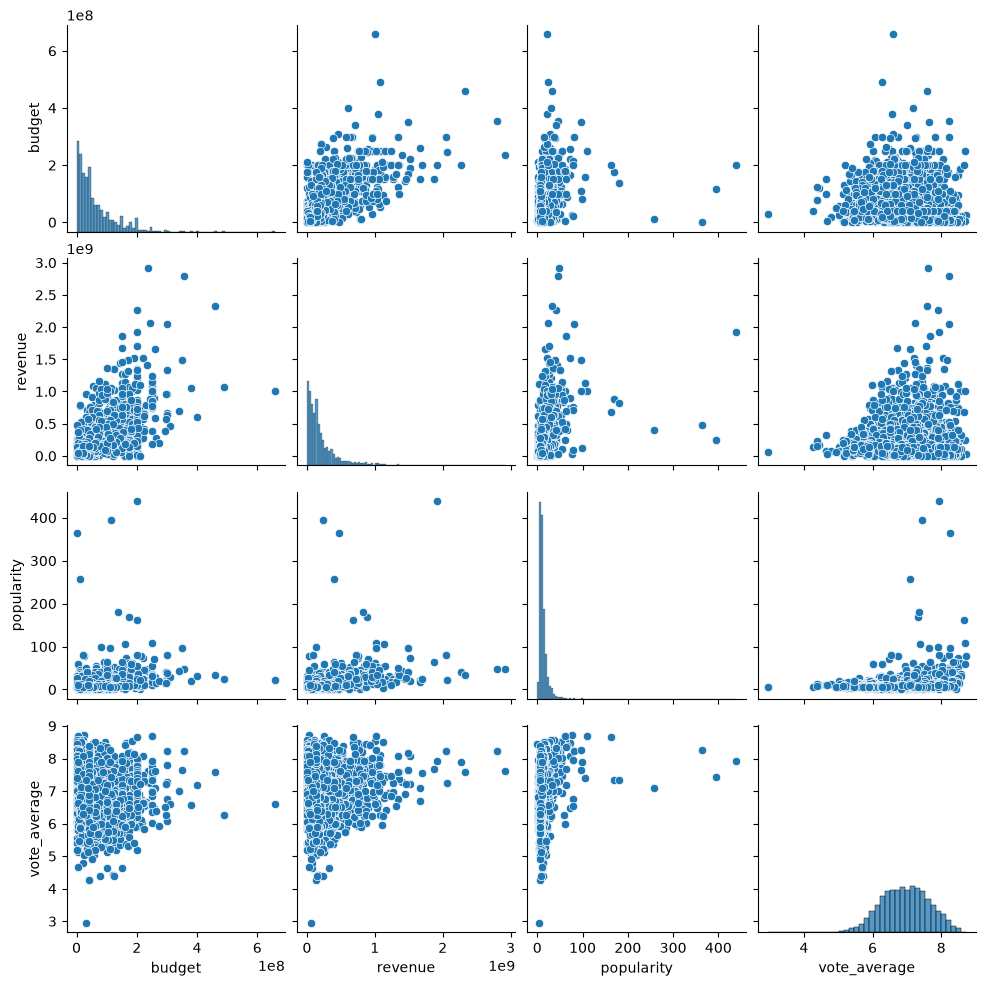

In [44]:
sns.pairplot(movies[['budget','revenue','popularity','vote_average']].dropna())
plt.show()

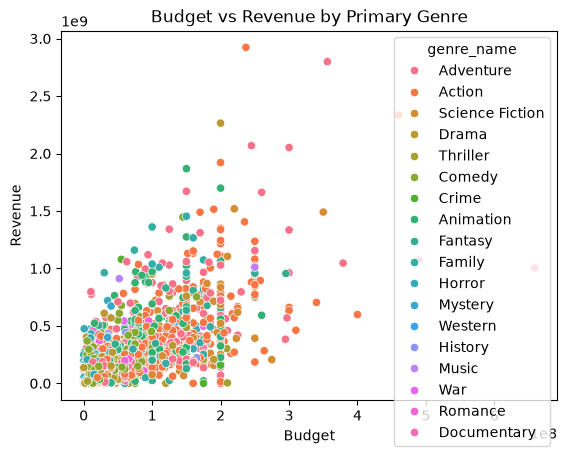

In [45]:
primary_genres = movie_genres.drop_duplicates(subset='movie_id')
data = primary_genres.merge(genres, on='genre_id')
data = data.merge(movies[['movie_id', 'budget', 'revenue']], on='movie_id')
sns.scatterplot(data=data, x='budget', y='revenue', hue='genre_name')
plt.title("Budget vs Revenue by Primary Genre")
plt.xlabel("Budget")
plt.ylabel("Revenue")
plt.show()

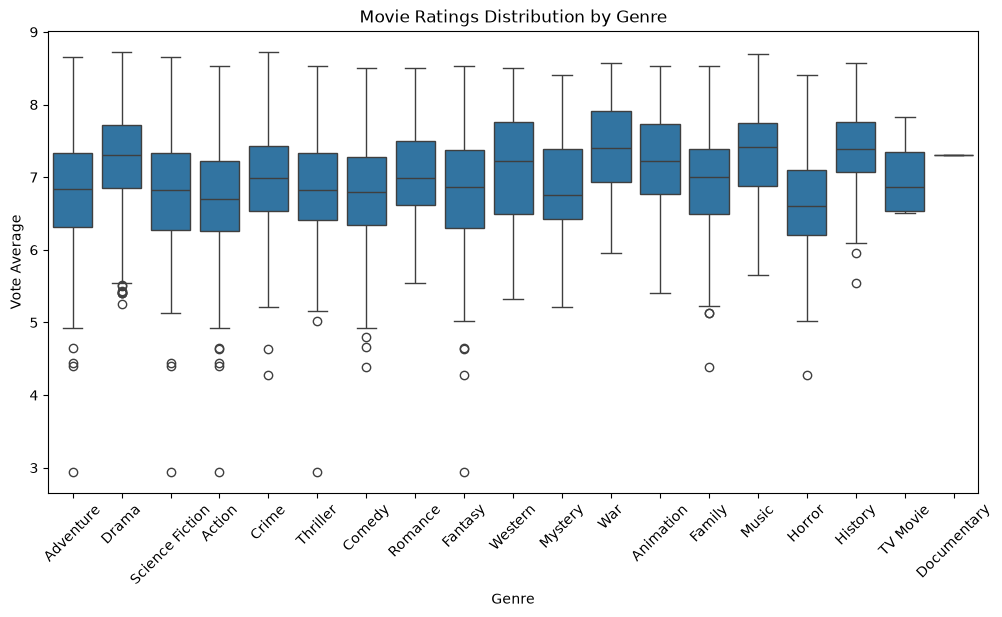

In [ ]:
data = movie_genres.merge(genres, on='genre_id')
data = data.merge(movies[['movie_id', 'vote_average']], on='movie_id')
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='genre_name', y='vote_average')
plt.title("Movie Ratings Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Vote Average")
plt.xticks(rotation=45)
plt.show()

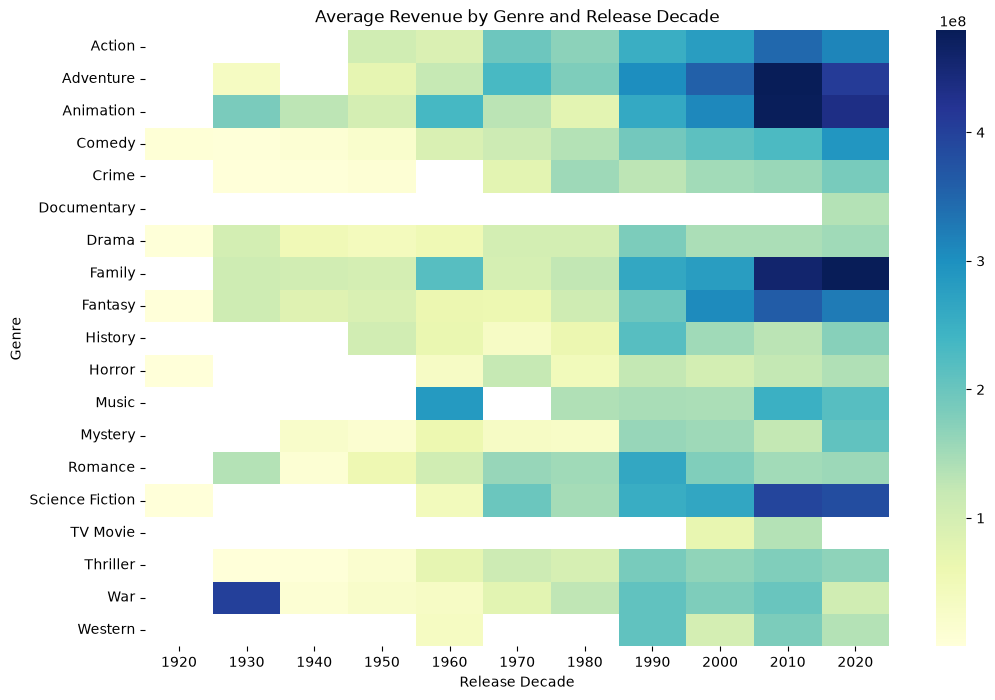

In [47]:
data = movie_genres.merge(genres, on='genre_id')
data = data.merge(movies[['movie_id', 'revenue', 'release_date']], on='movie_id')

data['year'] = pd.to_datetime(data['release_date']).dt.year
data['decade'] = (data['year'] // 10) * 10

pivot = data.pivot_table(
    values='revenue',
    index='genre_name',
    columns='decade',
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(pivot, cmap='YlGnBu')
plt.title("Average Revenue by Genre and Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Genre")
plt.show()